In [1]:
import pandas as pd

df = pd.read_csv("marketing_AB.csv")
print(df.shape)
df.head()

(588101, 7)


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


In [4]:
df = df.drop(columns=["Unnamed: 0"])
df.columns = ["user_id", "test_group", "converted", "total_ads", "most_ads_day", "most_ads_hour"]
df["converted"] = df["converted"].astype(int)

print("Duplicate users:", df["user_id"].duplicated().sum())

summary = df.groupby("test_group")["converted"].agg(["count", "sum", "mean"])
summary["conversion_pct"] = (summary["mean"] * 100).round(2)
summary = summary.rename(columns={"count": "users", "sum": "conversions"})
summary[["users", "conversions", "conversion_pct"]]

Duplicate users: 0


,users,conversions,conversion_pct
test_group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


In [5]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ad = df[df["test_group"] == "ad"]["converted"]
psa = df[df["test_group"] == "psa"]["converted"]

counts = [ad.sum(), psa.sum()]
nobs = [len(ad), len(psa)]

z_stat, p_value = proportions_ztest(counts, nobs, alternative="two-sided")
print("z-statistic:", round(z_stat, 2))
print("p-value:", p_value)

diff = ad.mean() - psa.mean()
low, high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1], compare="diff", method="wald")
print("Absolute lift (pp):", round(diff * 100, 2))
print("Relative lift (%):", round(diff / psa.mean() * 100, 1))
print("95% CI for the difference (pp):", round(low * 100, 2), "to", round(high * 100, 2))


z-statistic: 7.37
p-value: 1.7052807161559727e-13
Absolute lift (pp): 0.77
Relative lift (%): 43.1
95% CI for the difference (pp): 0.6 to 0.94


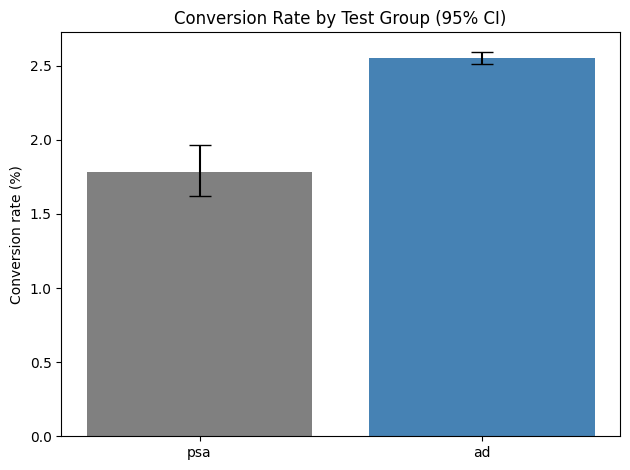

Extra conversions per 1,000,000 users: 7700
Range: 6000 to 9400


In [6]:
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

groups = ["psa", "ad"]
rates, lows, highs = [], [], []
for g in groups:
    s = df[df["test_group"] == g]["converted"]
    lo, hi = proportion_confint(s.sum(), len(s), method="wilson")
    rates.append(s.mean() * 100)
    lows.append(lo * 100)
    highs.append(hi * 100)

errors = [[r - l for r, l in zip(rates, lows)], [h - r for r, h in zip(rates, highs)]]

plt.bar(groups, rates, yerr=errors, capsize=8, color=["gray", "steelblue"])
plt.ylabel("Conversion rate (%)")
plt.title("Conversion Rate by Test Group (95% CI)")
plt.tight_layout()
plt.savefig("ab_conversion_by_group.png", dpi=150)
plt.show()

users = 1_000_000
print("Extra conversions per 1,000,000 users:", round(users * 0.0077))
print("Range:", round(users * 0.0060), "to", round(users * 0.0094))

In [7]:
df["ads_bucket"] = pd.cut(
    df["total_ads"],
    bins=[0, 5, 10, 25, 50, 100, df["total_ads"].max()],
    labels=["1-5", "6-10", "11-25", "26-50", "51-100", "100+"]
)

seg = df.groupby(["ads_bucket", "test_group"], observed=True)["converted"].agg(["count", "mean"])
seg["conv_pct"] = (seg["mean"] * 100).round(2)
seg[["count", "conv_pct"]]

count  conv_pct
ads_bucket test_group                  
1-5        ad          169962      0.25
           psa           7861      0.28
6-10       ad           79537      0.49
           psa           3415      0.67
11-25      ad          163135      1.02
           psa           6112      1.00
26-50      ad           85740      3.54
           psa           3273      2.66
51-100     ad           44149     11.63
           psa           1853      5.77
100+       ad           22054     17.14
           psa           1010     11.88

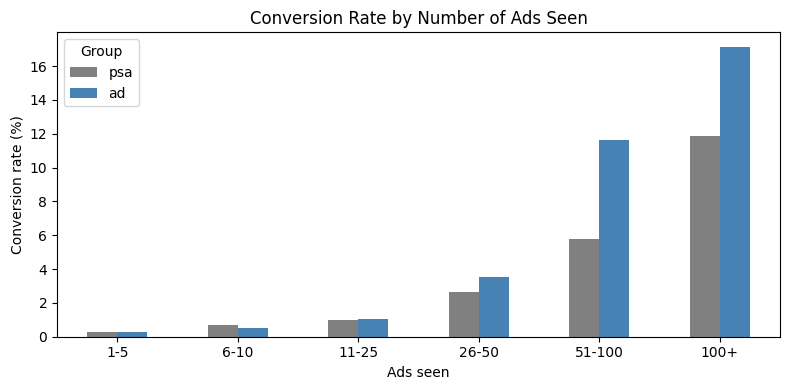

In [8]:
pivot = seg["conv_pct"].unstack("test_group")[["psa", "ad"]]

pivot.plot(kind="bar", color=["gray", "steelblue"], figsize=(8, 4))
plt.title("Conversion Rate by Number of Ads Seen")
plt.ylabel("Conversion rate (%)")
plt.xlabel("Ads seen")
plt.xticks(rotation=0)
plt.legend(title="Group")
plt.tight_layout()
plt.savefig("ab_conversion_by_ads_bucket.png", dpi=150)
plt.show()

In [9]:
df.to_csv("ab_clean.csv", index=False)
print("Saved!", df.shape)

Saved! (588101, 7)
